# Stage 3 – RAG for AI Governance

We compare three setups:

1. Text retrieval
2. Text retrieval with the Stage 1 graph
3. Graph retrieval with re-ranking

Data: AI Media Dataset, September 2024–August 2026. Code: `src/stage3_rag/`.


## 1. Setup

| Component | Setting |
|---|---|
| Q&A dataset | 120 passages, 66 articles, 240 questions |
| Sparse retrieval | TF-IDF, unigrams/bigrams, up to 120,000 features |
| Dense retrieval | `sentence-transformers/all-MiniLM-L6-v2` |
| Hybrid retrieval | Reciprocal-rank fusion |
| Graph | Stage 1 entity links and reviewed relations |
| Answer model | Local Ollama `llama3.2:latest` |
| Re-ranker | `cross-encoder/ms-marco-MiniLM-L-6-v2` |
| Answer evaluation | Same 60 test questions per setup |
| Automated scoring | Local `mistral:latest`, same 15 questions per setup |

- Choose retrieval settings on the development set.
- Report results on the test set.
- Leave `RUN_*` switches at `False` to load saved results.
- Enable a switch to repeat that experiment.


In [1]:
from pathlib import Path
import json
import os
import sys
import platform

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "notebooks/stage1_ai_governance/Stage1_AI_Governance.ipynb").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.stage3_rag.common import fingerprint, read_jsonl, sha256_file, write_json
from src.stage3_rag.data import prepare_qa_dataset
from src.stage3_rag.pipeline import prepare_data, build_index, run_retrieval_experiments, run_answer_experiments
from src.stage3_rag.snapshot import preflight_answers
from src.stage3_rag.generation import OllamaGenerator

SEED = 42
RUN_RETRIEVAL = False
RUN_ANSWER_GENERATION = False
RUN_AI_JUDGE = False
RUN_LIVE_QUERY = False
RESULTS_DIR = PROJECT_ROOT / "outputs/results/stage3"
FIGURES_DIR = PROJECT_ROOT / "outputs/figures/stage3"
DATA_DIR = PROJECT_ROOT / "data/processed/stage3"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)

print("Python:", sys.version.split()[0], "| machine:", platform.machine(), "| CPU threads:", torch.get_num_threads())
print("Answer model: local llama3.2 | Evaluation model: local Mistral")

from importlib.metadata import version
environment = {name: version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "torch", "transformers", "sentence-transformers", "networkx"]}
environment.update(python=sys.version.split()[0], machine=platform.machine(), cpu_threads=torch.get_num_threads())
write_json(RESULTS_DIR / "environment.json", environment)
display(pd.Series(environment, name="Version/runtime").to_frame())


Python: 3.12.4 | machine: arm64 | CPU threads: 4
Answer model: local llama3.2 | Evaluation model: local Mistral


,Version/runtime
numpy,2.2.6
pandas,3.1.0
scipy,1.17.1
scikit-learn,1.8.0
torch,2.10.0
transformers,4.57.6
sentence-transformers,5.2.3
networkx,3.6.1
python,3.12.4
machine,arm64


## 2. Data and chunks

- Reuse the Stage 1 Governance corpus and date range.
- Exclude articles marked irrelevant or uncertain. Other unreviewed articles still rely on dataset tags.
- Split text into 200-wordpiece chunks with 32-wordpiece overlap.
- Add up to 32 title wordpieces for dense retrieval. Check the 256-wordpiece input limit.
- Keep article IDs, original text positions and publication dates.
- Select the 120 Q&A passages from these chunks.


In [2]:
chunks, passages, graph, entity_articles, chunk_manifest = prepare_data(PROJECT_ROOT)

index = build_index(PROJECT_ROOT, chunks)

index_summary = json.loads((RESULTS_DIR / "index_summary.json").read_text())

display(pd.DataFrame({"Metric": ["Retrieval articles", "Retrieval chunks", "Selected passages", "Benchmark source articles", "Maximum dense input tokens", "Truncated dense inputs"],
                      "Value": [chunk_manifest["source_articles"], len(chunks), len(passages), passages.record_id.nunique(),
                                index.coverage_report["input_tokens_max"], index.coverage_report["embedding_truncated_chunks"]]}))
assert index.coverage_report["embedding_truncated_chunks"] == 0

assert index.coverage_report["tokenizer_verified"]

display(passages[["passage_id", "record_id", "date", "title", "split"]].head(8))

print("Index cache hit:", index.index_cache_hit)

print("Original index-build seconds:", index_summary.get("initial_index_build_seconds"))


Building/loading sparse and dense indices for 188,873 chunks...
Index cache hit: True
Original index-build seconds: 2013.7767086250242


,Metric,Value
0,Retrieval articles,12805
1,Retrieval chunks,188873
2,Selected passages,120
3,Benchmark source articles,66
4,Maximum dense input tokens,238
5,Truncated dense inputs,0


,passage_id,record_id,date,title,split
0,0492f26018960b4cfeb858fb,144536,2024-09-18,Why We Must Approach AI Like the Automobile,development
1,890134dd1144c135fb4e5861,144536,2024-09-18,Why We Must Approach AI Like the Automobile,development
2,973f2ee3837fde80e13ef64f,144536,2024-09-18,Why We Must Approach AI Like the Automobile,development
3,82d7f1d765e4ad829ecf08da,151969,2025-05-12,AI can guess racial categories from heart scan...,development
4,ba0e9ec6df820cf84b5ae775,169583,2025-06-06,microsoft/NatureLM-8x7B-Inst · Hugging Face,development
5,7e1727e31ce7b03a808aea3a,110621,2025-08-05,Generative AI – Changing the game with KymChat,development
6,9045857d5c9a74563b5e8694,110621,2025-08-05,Generative AI – Changing the game with KymChat,development
7,5ceaf99ce100cb8858921f54,46965,2025-08-06,"Trump’s AI Action Plan, Explained",development


## 3. Q&A dataset

- 120 passages, two questions each: 240 pairs.
- Five types: factual, temporal, relational, analytical and comparative.
- Check questions, answers and quotes against the source passage.


In [3]:
qas, _, qa_manifest = prepare_qa_dataset(PROJECT_ROOT, passages)

display(pd.crosstab(qas["category"], qas["split"]).reindex(
    ["factual", "temporal", "relational", "analytical", "comparative"]))

display(qas[["qa_id", "category", "question", "reference_answer", "gold_evidence"]].head(5))

assert qas.groupby("record_id")["split"].nunique().max() == 1
assert qas.qa_id.is_unique


split,development,test
category,,
factual,11,49
temporal,7,25
relational,11,34
analytical,18,39
comparative,15,31


,qa_id,category,question,reference_answer,gold_evidence
0,q_0492f26018960b4cfeb858fb_1,factual,Which three ethical priorities does the articl...,"It calls for fairness, transparency, and accou...","We must also ensure AI development is ethical,..."
1,q_0492f26018960b4cfeb858fb_2,comparative,How do the proposed AI benefits differ between...,Education would adapt learning to individual n...,Personalized education powered by AI can adapt...
2,q_890134dd1144c135fb4e5861_1,analytical,Why does the author advocate digital inclusion...,They would provide tools and resources to part...,This requires advocating for digital inclusion...
3,q_890134dd1144c135fb4e5861_2,relational,Which groups should jointly create the AI regu...,"Governments, businesses, and civil society sho...","Governments, businesses, and civil society mus..."
4,q_973f2ee3837fde80e13ef64f_1,factual,Which governance standards does the article ca...,"It calls for standards for data privacy, AI tr...","This means setting standards for data privacy,..."


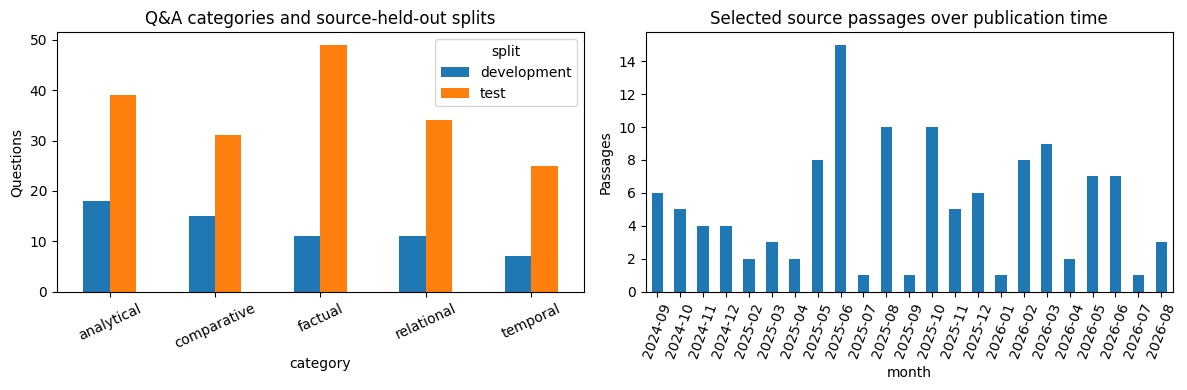

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

pd.crosstab(qas["category"], qas["split"]).plot.bar(ax=axes[0], rot=25)

axes[0].set_title("Q&A categories and source-held-out splits")

axes[0].set_ylabel("Questions")

passages.assign(month=pd.to_datetime(passages.date).dt.to_period("M").astype(str)).groupby("month").size().plot.bar(ax=axes[1], rot=70)

axes[1].set_title("Selected source passages over publication time")

axes[1].set_ylabel("Passages")

fig.tight_layout()

fig.savefig(FIGURES_DIR / "dataset_coverage.png", dpi=140, bbox_inches="tight")

plt.show()


## 4. Retrieval baselines

- **Sparse:** TF-IDF for keywords and names.
- **Dense:** MiniLM for similar meanings.
- **Hybrid:** combine both rankings.
- Select the retriever by development MRR@4, then Recall@4.
- Keep all questions from one article in the same split.
- Index article text, not questions or reference answers.
- Measure Recall@4, MRR@4, nDCG@4 and source-article hit rate.
- Gold labels identify the chosen evidence chunk. Other chunks may also contain a valid answer.


In [5]:
if RUN_RETRIEVAL:
    run_retrieval_experiments(PROJECT_ROOT, index, qas, graph, entity_articles)

if not (RESULTS_DIR / "retrieval_manifest.json").exists():
    raise RuntimeError("Run the retrieval experiment first: python -m src.stage3_rag.pipeline --retrieval")

retrieval_manifest = json.loads((RESULTS_DIR / "retrieval_manifest.json").read_text())

if retrieval_manifest["qa_fingerprint"] != fingerprint(qas.to_dict("records")):
    raise RuntimeError("Q&A snapshot changed. Rerun retrieval before displaying or generating evaluation results.")

selection = pd.read_csv(RESULTS_DIR / "development_retriever_comparison.csv")

display(selection.loc[selection.category.eq("all"), ["variant", "n_questions", "recall_at_k", "mrr", "ndcg_at_k", "gold_record_retrieved"]])

print("Validation-selected text retriever:", retrieval_manifest["selected_text_mode"])


Validation-selected text retriever: hybrid


,variant,n_questions,recall_at_k,mrr,ndcg_at_k,gold_record_retrieved
0,dense,62,0.209677,0.166667,0.177802,0.290323
6,hybrid,62,0.370968,0.267473,0.293811,0.467742
12,sparse,62,0.338710,0.248656,0.271729,0.451613


## 5. Graph retrieval

- Match question entities to the Stage 1 graph.
- Find linked articles and rank their passages against the question.
- Use co-occurrence for retrieval only; a shared mention is not a factual relationship.
- Keep reviewed relations with their source article, date and quote.
- Include a relation in the prompt only when its quote is visible in a retrieved passage.
- Direct article links also cover relation entities missing from the NER index.


Reviewed semantic source assertions available: 22
NER entity/article memberships available: 138690
Graph storage: 855 nodes / 14226 directed storage edges


,subject,relation,object,record_id,date,evidence,review_method
0,ORG::Google,DEVELOPS,MODEL::Gemma,44425,2025-05-09,"Gemma is a family of lightweight, state-of-the...",ai_assisted
1,ORG::Google,DEVELOPS,PRODUCT::Opal,171766,2025-10-08,Google has expanded the release of its vibe-co...,ai_assisted
2,ORG::Google,DEVELOPS,STANDARD::Secure AI Framework,69083,2026-01-17,"At Google, we know that security and data priv...",ai_assisted
3,ORG::Google,DEVELOPS,PRODUCT::Gemini CLI,51569,2026-06-10,Google built Gemini CLI with a terminal-first ...,ai_assisted
4,ORG::OpenAI,DEVELOPS,MODEL::GPT,74687,2024-11-08,"OpenAI released its first GPT model in 2018, a...",ai_assisted
5,ORG::Microsoft,COMPLIES_WITH,STANDARD::Responsible AI Standard,104296,2025-08-21,Microsoft embeds Responsible AI principles int...,ai_assisted
6,ORG::European Union,ADOPTS,LAW::EU AI Act,67189,2026-05-07,"The AI Act, adopted in 2024, is the EU’s centr...",ai_assisted
7,LAW::EU AI Act,REGULATES,TECHNOLOGY::Artificial Intelligence,172313,2024-09-26,The EU AI Act uses a risk-based classification...,ai_assisted


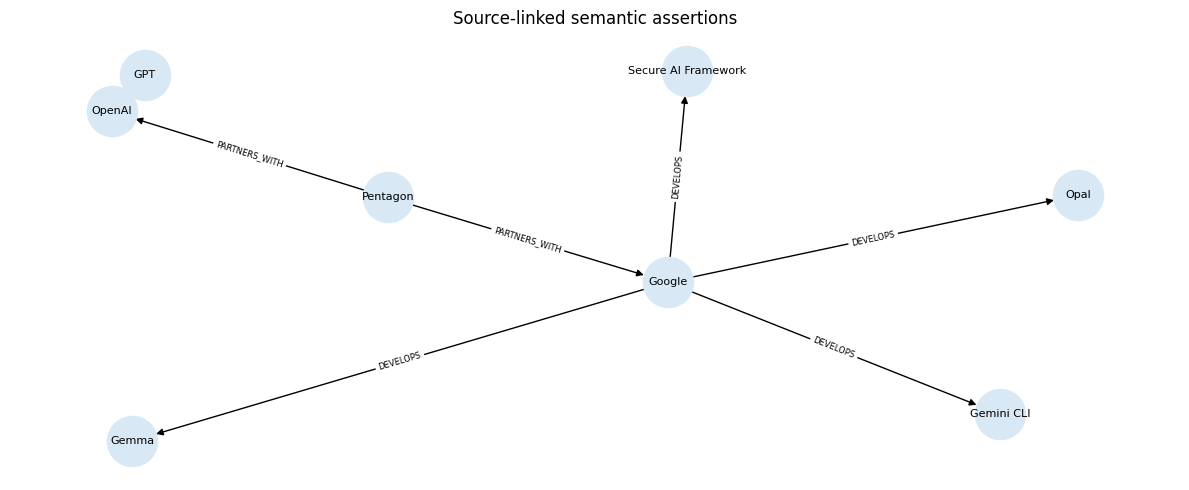

In [6]:
semantic_edges = []

for source, target, attrs in graph.edges(data=True):
    if attrs.get("fact_assertion") is True:
        semantic_edges.append({"subject": source, "relation": attrs["relation"], "object": target,
                               "record_id": attrs["record_id"], "date": attrs["date"],
                               "evidence": attrs["evidence"], "review_method": attrs["review_method"]})
        
display(pd.DataFrame(semantic_edges).head(8))

print("Reviewed semantic source assertions available:", len(semantic_edges))

print("NER entity/article memberships available:", len(entity_articles))

print("Graph storage:", graph.number_of_nodes(), "nodes /", graph.number_of_edges(), "directed storage edges")

# Semantic graph
semantic_view = nx.DiGraph()

for row in semantic_edges:
    semantic_view.add_edge(row["subject"], row["object"], relation=row["relation"])

if semantic_view.number_of_edges():
    component = max(nx.weakly_connected_components(semantic_view), key=len)
    nodes = sorted(component, key=lambda node: (-semantic_view.degree(node), node))[:12]
    view = semantic_view.subgraph(nodes)
    positions = nx.spring_layout(view, seed=SEED)
    fig, ax = plt.subplots(figsize=(12, 5))

    nx.draw_networkx(view, positions, ax=ax, labels={node:node.split("::", 1)[-1] for node in view},
                     node_size=1300, node_color="#d9e8f5", font_size=8, arrows=True)
    nx.draw_networkx_edge_labels(view, positions, ax=ax, edge_labels=nx.get_edge_attributes(view, "relation"), font_size=6)
    ax.set_title("Source-linked semantic assertions")

    ax.axis("off")

    fig.tight_layout(); fig.savefig(FIGURES_DIR / "semantic_graph_example.png", dpi=140, bbox_inches="tight")
    
    plt.show()


## 6. Re-ranking

- Development results show relevant chunks in the top 20 that miss the top four.
- Re-rank the same 20 graph-retrieval candidates with the cross encoder.
- Keep four passages for the answer.
- Compare with graph retrieval using the same candidate and context limits.
- Choose settings before running the test comparison.


,Metric,Value
0,Development Recall@4,0.370968
1,Development candidate Recall@20,0.645161
2,Candidate-to-context recall gap,0.274194


,variant,n_questions,recall_at_k,mrr,ndcg_at_k,gold_record_retrieved
0,graph,178,0.539326,0.431180,0.458304,0.629213
6,graph_rerank,178,0.724719,0.672285,0.685616,0.786517
12,text_only,178,0.550562,0.435393,0.464445,0.634831


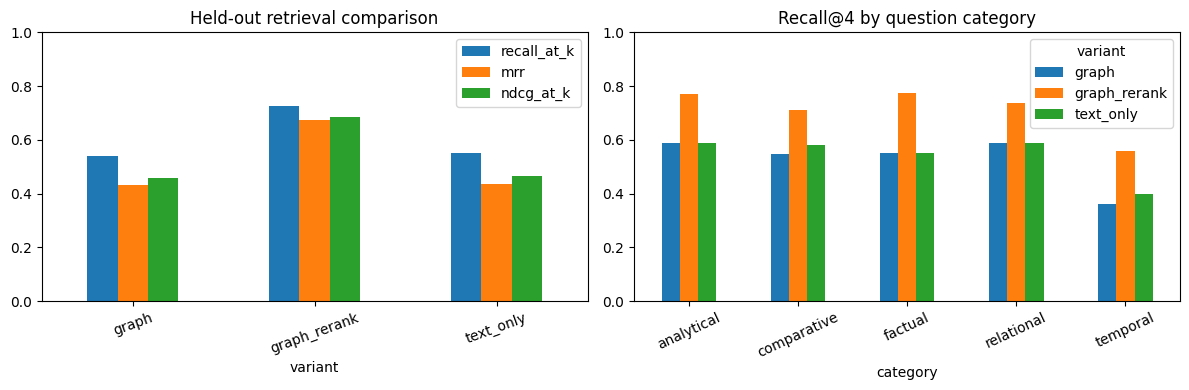

In [7]:
enhancement = json.loads((RESULTS_DIR / "enhancement_design.json").read_text())

display(pd.DataFrame({"Metric": ["Development Recall@4", "Development candidate Recall@20", "Candidate-to-context recall gap"],
                      "Value": [enhancement["development_recall_at_4"], enhancement["development_candidate_recall_at_20"], enhancement["candidate_context_recall_gap"]]}))
retrieval_results = pd.read_csv(RESULTS_DIR / "test_retrieval_summary.csv")

display(retrieval_results.loc[retrieval_results.category.eq("all"), ["variant", "n_questions", "recall_at_k", "mrr", "ndcg_at_k", "gold_record_retrieved"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

retrieval_results.loc[retrieval_results.category.eq("all")].set_index("variant")[["recall_at_k", "mrr", "ndcg_at_k"]].plot.bar(ax=axes[0], rot=20, ylim=(0, 1))
axes[0].set_title("Held-out retrieval comparison")

retrieval_results.loc[retrieval_results.category.ne("all")].pivot(index="category", columns="variant", values="recall_at_k").plot.bar(ax=axes[1], rot=25, ylim=(0, 1))
axes[1].set_title("Recall@4 by question category")

fig.tight_layout(); fig.savefig(FIGURES_DIR / "retrieval_comparison.png", dpi=140, bbox_inches="tight")

plt.show()


## 7. Answer generation

- Same Llama 3.2 model for all setups: seed 42, temperature 0, four passages.
- Supply source IDs and publication dates. Publication dates are not necessarily event dates.
- Return an answer, citations, an optional quote and an insufficient-evidence flag.
- Check supplied quotes against the cited text.
- Limit source input to 12,000 characters and five supported graph facts.
- Keep failed outputs in the results.
- Cache responses with their inputs, model version, token counts and timings.


In [8]:
answer_sample, test_runs, checked_qa_manifest = preflight_answers(PROJECT_ROOT)

if RUN_ANSWER_GENERATION:
    run_answer_experiments(PROJECT_ROOT, run_judge=RUN_AI_JUDGE)
if not (RESULTS_DIR / "answer_runs.json").exists():
    raise RuntimeError("Run local answers first: python -m src.stage3_rag.pipeline --answers --judge")

answer_runs = json.loads((RESULTS_DIR / "answer_runs.json").read_text())

answer_manifest = json.loads((RESULTS_DIR / "answer_manifest.json").read_text())

for key, path in {
    "answer_sample_sha256": DATA_DIR / "answer_evaluation_sample.jsonl",
    "retrieval_runs_sha256": RESULTS_DIR / "test_retrieval_runs.json",
    "answer_runs_sha256": RESULTS_DIR / "answer_runs.json",
    "answer_per_question_sha256": RESULTS_DIR / "answer_per_question.csv",
    "answer_summary_sha256": RESULTS_DIR / "answer_summary.csv",
}.items():
    if answer_manifest.get(key) != sha256_file(path):
        raise RuntimeError("Answer snapshot changed. Rerun local answers before displaying the comparison.")
if answer_manifest["qa_label_status"] != checked_qa_manifest["evaluation_status"]:
    raise RuntimeError("Answer label status differs from the current Q&A review snapshot.")
assert answer_manifest["generation_code_sha256"] == sha256_file(PROJECT_ROOT / "src/stage3_rag/generation.py")
assert answer_manifest["evaluation_code_sha256"] == sha256_file(PROJECT_ROOT / "src/stage3_rag/evaluation.py")

display(answer_sample.groupby("category").size().rename("Paired answer questions").to_frame())

print("Answer model identity:", answer_manifest["generator"])


print("Different question-generation and answer models:", answer_manifest["different_qa_and_answer_models"])


Answer model identity: {'requested_model': 'llama3.2:latest', 'digest': 'a80c4f17acd55265feec403c7aef86be0c25983ab279d83f3bcd3abbcb5b8b72', 'name': 'llama3.2:latest', 'details': {'parent_model': '', 'format': 'gguf', 'family': 'llama', 'families': ['llama'], 'parameter_size': '3.2B', 'quantization_level': 'Q4_K_M', 'context_length': 131072, 'embedding_length': 3072}}
Different question-generation and answer models: True


,Paired answer questions
category,
analytical,12
comparative,12
factual,12
relational,12
temporal,12


## 8. Evaluation

- Retrieval: all 178 test questions.
- Answers: the same 60 questions per setup, 12 per category.
- Mistral scores: the same 15 questions per setup, three per category.
- The evaluator sees the question, answer, citations and retrieved text, without the reference answer.

| Metric | What it measures |
|---|---|
| Token F1 | Word overlap with the reference answer |
| Citation validity | Whether cited source IDs exist |
| Quote grounding | Exact quote present in a cited passage |
| Gold context coverage | Chosen evidence chunk in the answer context |
| Temporal proxies | Reference years and publication dates mentioned |
| Faithfulness | Claims supported by the sources, 1–5 |
| Relevance | Answer addresses the question, 1–5 |
| Context grounding | Appropriate use of evidence and citations, 1–5 |
| Temporal grounding | Supported dates and chronology, 1–5 |

- `generation_success`: JSON, citation and supplied-quote checks passed.
- A missing optional quote scores zero on quote grounding for a non-abstaining answer.
- Keep failures and report the number of scores per metric. Missing scores stay missing.
- Temporal scoring covers three questions per setup.
- Automated scores are estimates. Quote matches alone do not establish a correct answer.
- Differences are descriptive; no statistical significance test was run.


,variant,n_questions,generation_success,token_f1,citation_validity,gold_context_coverage,exact_quote_grounding_proxy,abstention_rate
0,graph,60,0.766667,0.262440,1.000000,0.483333,0.633333,0.0
6,graph_rerank,60,0.833333,0.366639,0.983333,0.683333,0.700000,0.0
12,text_only,60,0.700000,0.257490,1.000000,0.483333,0.566667,0.0


,variant,faithfulness,faithfulness_n,relevance,relevance_n,context_grounding,context_grounding_n,temporal_grounding,temporal_grounding_n
0,graph,4.000000,15,4.6,15,4.266667,15,3.000000,3
6,graph_rerank,4.333333,15,4.8,15,4.333333,15,4.666667,3
12,text_only,4.200000,15,4.8,15,4.266667,15,3.666667,3


,variant,category,n_questions,token_f1,token_f1_n,citation_validity,citation_validity_n,exact_quote_grounding_proxy,exact_quote_grounding_proxy_n,faithfulness,faithfulness_n,relevance,relevance_n,context_grounding,context_grounding_n,temporal_grounding,temporal_grounding_n
1,graph,analytical,12,0.230479,12,1.000000,12,0.833333,12,4.666667,3,5.000000,3,4.333333,3,NaN,0
7,graph_rerank,analytical,12,0.283647,12,1.000000,12,0.916667,12,4.666667,3,5.000000,3,4.666667,3,NaN,0
13,text_only,analytical,12,0.234302,12,1.000000,12,0.750000,12,4.666667,3,5.000000,3,4.333333,3,NaN,0
2,graph,comparative,12,0.338192,12,1.000000,12,0.750000,12,4.666667,3,5.000000,3,4.666667,3,NaN,0
8,graph_rerank,comparative,12,0.396123,12,1.000000,12,0.750000,12,5.000000,3,5.000000,3,4.666667,3,NaN,0
14,text_only,comparative,12,0.313766,12,1.000000,12,0.666667,12,4.666667,3,5.000000,3,4.666667,3,NaN,0
3,graph,factual,12,0.260534,12,1.000000,12,0.500000,12,3.666667,3,4.666667,3,4.333333,3,NaN,0
9,graph_rerank,factual,12,0.438991,12,1.000000,12,0.583333,12,4.666667,3,5.000000,3,4.333333,3,NaN,0
15,text_only,factual,12,0.281047,12,1.000000,12,0.416667,12,3.666667,3,4.666667,3,4.666667,3,NaN,0
4,graph,relational,12,0.303218,12,1.000000,12,0.583333,12,3.666667,3,4.000000,3,4.000000,3,NaN,0


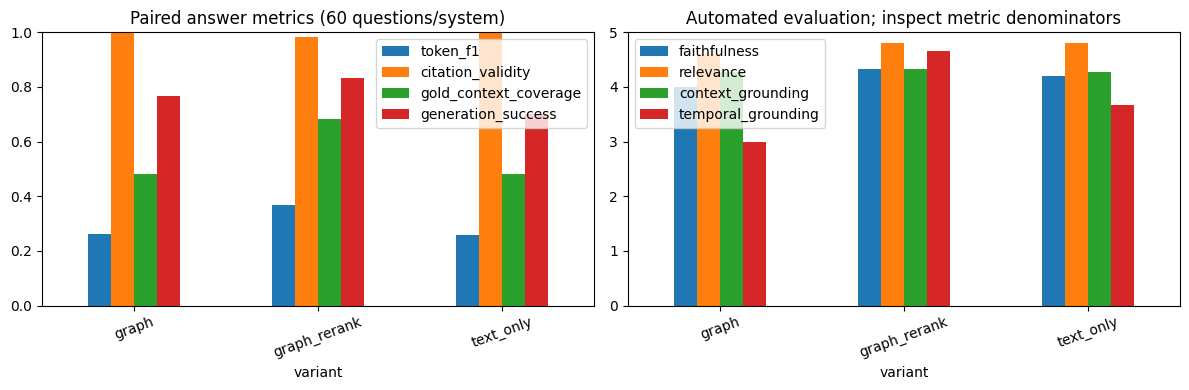

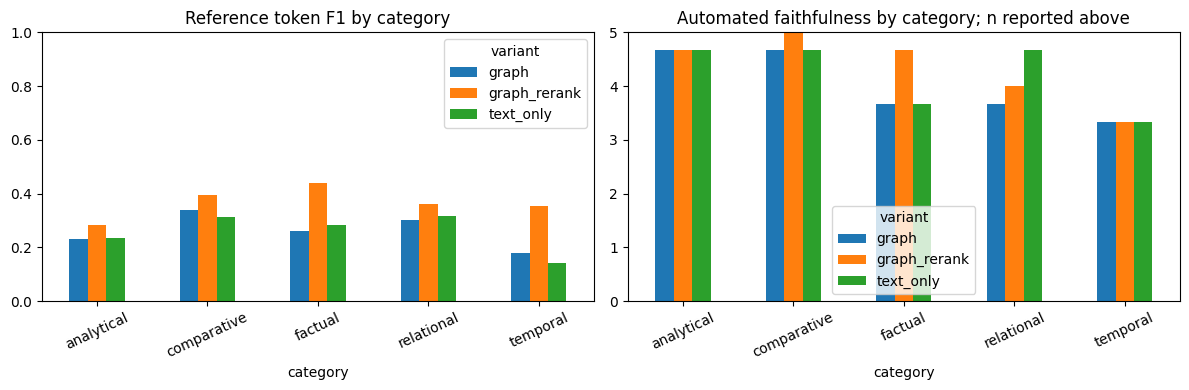

In [9]:
answer_results = pd.read_csv(RESULTS_DIR / "answer_summary.csv")

answer_rows = pd.read_csv(RESULTS_DIR / "answer_per_question.csv")

metrics = ["variant", "n_questions", "generation_success", "token_f1", "citation_validity", "gold_context_coverage", "exact_quote_grounding_proxy", "abstention_rate"]
display(answer_results.loc[answer_results.category.eq("all"), metrics])

judge_metrics = ["variant", "ai_judge_faithfulness", "ai_judge_faithfulness_n", "ai_judge_relevance", "ai_judge_relevance_n", "ai_judge_context_grounding", "ai_judge_context_grounding_n", "ai_judge_temporal_grounding", "ai_judge_temporal_grounding_n"]
display(answer_results.loc[answer_results.category.eq("all"), judge_metrics].rename(columns=lambda name: name.removeprefix("ai_judge_")))

category_columns = ["variant", "category", "n_questions", "token_f1", "token_f1_n",
    "citation_validity", "citation_validity_n", "exact_quote_grounding_proxy", "exact_quote_grounding_proxy_n",
    "ai_judge_faithfulness", "ai_judge_faithfulness_n", "ai_judge_relevance", "ai_judge_relevance_n",
    "ai_judge_context_grounding", "ai_judge_context_grounding_n", "ai_judge_temporal_grounding", "ai_judge_temporal_grounding_n"]

display(answer_results.loc[answer_results.category.ne("all"), category_columns].sort_values(["category", "variant"]).rename(columns=lambda name: name.removeprefix("ai_judge_")))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

answer_results.loc[answer_results.category.eq("all")].set_index("variant")[["token_f1", "citation_validity", "gold_context_coverage", "generation_success"]].plot.bar(ax=axes[0], rot=20, ylim=(0, 1))
axes[0].set_title("Paired answer metrics (60 questions/system)")

answer_results.loc[answer_results.category.eq("all")].set_index("variant")[["ai_judge_faithfulness", "ai_judge_relevance", "ai_judge_context_grounding", "ai_judge_temporal_grounding"]].rename(columns=lambda name: name.removeprefix("ai_judge_")).plot.bar(ax=axes[1], rot=20, ylim=(0, 5))
axes[1].set_title("Automated evaluation; inspect metric denominators")

fig.tight_layout(); fig.savefig(FIGURES_DIR / "answer_comparison.png", dpi=140, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

category_results = answer_results.loc[answer_results.category.ne("all")]

category_results.pivot(index="category", columns="variant", values="token_f1").plot.bar(ax=axes[0], rot=25, ylim=(0, 1))
axes[0].set_title("Reference token F1 by category")

category_results.pivot(index="category", columns="variant", values="ai_judge_faithfulness").plot.bar(ax=axes[1], rot=25, ylim=(0, 5))
axes[1].set_title("Automated faithfulness by category; n reported above")

fig.tight_layout(); fig.savefig(FIGURES_DIR / "answer_categories.png", dpi=140, bbox_inches="tight")

plt.show()


In [10]:
# Paired effects
paired_effects = []

for label, before, after in [("Graph vs text", "text_only", "graph"), ("Re-ranking vs graph", "graph", "graph_rerank")]:
    for metric, frame in [("recall_at_k", pd.read_csv(RESULTS_DIR / "test_retrieval_per_question.csv")),
                          ("token_f1", answer_rows), ("ai_judge_faithfulness", answer_rows)]:
        pivot = frame.pivot(index="qa_id", columns="variant", values=metric)
        valid = pivot[[before, after]].dropna()
        paired_effects.append({"Comparison": label, "Metric": metric.removeprefix("ai_judge_"), "Paired questions": len(valid),
                               "Mean difference": (valid[after] - valid[before]).mean()})
        
display(pd.DataFrame(paired_effects))

print("Score differences are descriptive; no significance claim is made.")


Score differences are descriptive; no significance claim is made.


,Comparison,Metric,Paired questions,Mean difference
0,Graph vs text,recall_at_k,178,-0.011236
1,Graph vs text,token_f1,60,0.004949
2,Graph vs text,faithfulness,15,-0.200000
3,Re-ranking vs graph,recall_at_k,178,0.185393
4,Re-ranking vs graph,token_f1,60,0.104200
5,Re-ranking vs graph,faithfulness,15,0.333333


In [11]:
# Held-out interpretation
r_overall = retrieval_results.loc[retrieval_results.category.eq("all")].set_index("variant")
a_overall = answer_results.loc[answer_results.category.eq("all")].set_index("variant")


graph_recall_delta = r_overall.loc["graph", "recall_at_k"] - r_overall.loc["text_only", "recall_at_k"]

rerank_recall_delta = r_overall.loc["graph_rerank", "recall_at_k"] - r_overall.loc["graph", "recall_at_k"]

graph_f1_delta = a_overall.loc["graph", "token_f1"] - a_overall.loc["text_only", "token_f1"]

rerank_f1_delta = a_overall.loc["graph_rerank", "token_f1"] - a_overall.loc["graph", "token_f1"]

display(Markdown(
    f"**Test results**\n\n"
    f"- Graph vs text: Recall@4 **{graph_recall_delta * 100:+.1f} pp**; token F1 **{graph_f1_delta:+.3f}**.\n"
    f"- Re-ranking vs graph: Recall@4 **{rerank_recall_delta * 100:+.1f} pp**; token F1 **{rerank_f1_delta:+.3f}**.\n"
    f"- Development Recall@20 minus Recall@4: **{enhancement['candidate_context_recall_gap'] * 100:.1f} pp**."
))

display(Markdown(
    "**Trend monitoring**\n\n"
    "- Use publication dates to track coverage over time.\n"
    "- Graph links connect actors, standards and articles.\n"
    "- Re-ranking adds a scoring step to choose the four passages.\n"
    "- These results apply to this test set."
))


**Test results**

- Graph vs text: Recall@4 **-1.1 pp**; token F1 **+0.005**.
- Re-ranking vs graph: Recall@4 **+18.5 pp**; token F1 **+0.104**.
- Development Recall@20 minus Recall@4: **27.4 pp**.

**Trend monitoring**

- Use publication dates to track coverage over time.
- Graph links connect actors, standards and articles.
- Re-ranking adds a scoring step to choose the four passages.
- These results apply to this test set.

## 9. Examples and limits

- Examples follow category and ID order.
- Check the answer against the quoted sources and dates.
- The graph has few reviewed relations and many co-occurrences.
- Dataset tags remain weak labels outside the reviewed sample.
- A few passages are multilingual; the retrieval models mainly target English.
- Results describe this test set, not the whole corpus.
- The Q&A benchmark is provisional.


In [12]:
for category in ["factual", "temporal"]:
    qa = answer_sample.loc[answer_sample.category.eq(category)].sort_values("qa_id").iloc[0]
    display(Markdown(f"**{category.title()} question:** {qa['question']}"))
    for variant in ["text_only", "graph", "graph_rerank"]:
        result = answer_runs[variant][qa["qa_id"]]
        display(Markdown(f"**{variant}** (`{result['status']}`): {result['answer']}"))
        display(pd.DataFrame(result.get("context", []))[["passage_id", "record_id", "date", "title"]])
        if result.get("judge"):
            print("Automated evaluation:", result["judge"].get("explanation", ""))


**Factual question:** Which security measures are recommended for sensitive insurance documents processed with IDP?

**text_only** (`invalid_quote`): tamper-proof audit trails with automatic logging and timestamping

,passage_id,record_id,date,title
0,1,74755,2025-12-08,Intelligent Document Processing (IDP) in Insur...
1,2,74755,2025-12-08,Intelligent Document Processing (IDP) in Insur...
2,3,74755,2025-12-08,Intelligent Document Processing (IDP) in Insur...
3,4,74755,2025-12-08,Intelligent Document Processing (IDP) in Insur...


**graph** (`invalid_quote`): tamper-proof audit trails with automatic logging and timestamping

,passage_id,record_id,date,title
0,1,74755,2025-12-08,Intelligent Document Processing (IDP) in Insur...
1,2,74755,2025-12-08,Intelligent Document Processing (IDP) in Insur...
2,3,74755,2025-12-08,Intelligent Document Processing (IDP) in Insur...
3,4,74755,2025-12-08,Intelligent Document Processing (IDP) in Insur...


**graph_rerank** (`invalid_quote`): access controls, encryption, secure storage, and adherence to regulatory standards like GDPR or HIPAA

... (4 outputs left out)

**graph** (`ok`): Insufficient information, no mention of a specific law or signing date for Montana's governor.

,passage_id,record_id,date,title
0,1,68192,2025-03-25,Virginia vetoes AI bill in latest push toward ...
1,2,68037,2024-09-30,California governor vetoed SB 1047. What’s nex...
2,3,68037,2024-09-30,California governor vetoed SB 1047. What’s nex...
3,4,104063,2026-05-11,Major Developments Put Colorado’s AI Law on Ic...


**graph_rerank** (`ok`): May 5, 2025

,passage_id,record_id,date,title
0,1,152030,2025-06-13,"Protecting the vulnerable, or automating harm?..."
1,2,104064,2026-05-26,Colorado’s AI Law Gets Major Rewrite – What No...
2,3,68037,2024-09-30,California governor vetoed SB 1047. What’s nex...
3,4,68495,2026-01-08,4 CIO trends to watch in 2026


In [13]:
# Evidence coverage
usage = []
for variant, current in answer_runs.items():
    usage.append({"variant": variant, "answers": len(current),
                  "answers_with_graph_facts": sum(int(r.get("graph_fact_count", 0)) > 0 for r in current.values()),
                  "answers_without_quote": sum(not r.get("supporting_quote") for r in current.values()),
                  "mean_prompt_tokens": pd.Series([r.get("prompt_eval_count") for r in current.values()]).mean(),
                  "mean_generated_tokens": pd.Series([r.get("eval_count") for r in current.values()]).mean(),
                  "mean_original_generation_seconds": pd.Series([r.get("inference_wall_seconds") for r in current.values()]).mean()})
display(pd.DataFrame(usage))
fact_prompts = sum(row["answers_with_graph_facts"] for row in usage)
if fact_prompts == 0:
    display(Markdown("**Graph coverage:** No reviewed relation entered the answer prompts in this sample. The graph comparison therefore measures retrieval expansion."))
else:
    print("Answer prompts containing reviewed semantic facts:", fact_prompts)
failures = answer_rows.loc[answer_rows.status.ne("ok"), ["variant", "qa_id", "category", "status"]]
display(failures.head(10))
print("Generation failures:", len(failures), "/", len(answer_rows))

# Citation and quote checks
for variant, current in answer_runs.items():
    failed_ids = sorted(qid for qid, result in current.items() if result.get("status") != "ok")
    if not failed_ids:
        continue
    result = current[failed_ids[0]]
    quote = result.get("supporting_quote") or ""
    display(Markdown(f"**Validation example — {variant}, {result['status']}:** {result['answer']}"))
    print("Cited passage IDs:", result.get("citations"), "| Proposed quote:", quote)
    display(pd.DataFrame([{
        "passage_id": source["passage_id"], "record_id": source["record_id"],
        "cited": source["passage_id"] in result.get("citations", []),
        "quote_present": bool(quote and quote in source["text"]), "title": source["title"]
    } for source in result.get("context", [])]))


Generation failures: 42 / 180
Cited passage IDs: [3] | Proposed quote: All processing activities create tamper-proof audit trails with automatic logging and timestamping, supporting regulatory compliance requirements and enabling comprehensive review for audit purposes.
Cited passage IDs: [3] | Proposed quote: All processing activities create tamper-proof audit trails with automatic logging and timestamping, supporting regulatory compliance requirements and enabling comprehensive review for audit purposes.
Cited passage IDs: [1] | Proposed quote: Maintaining strong data security is critical.


,variant,answers,answers_with_graph_facts,answers_without_quote,mean_prompt_tokens,mean_generated_tokens,mean_original_generation_seconds
0,text_only,60,0,8,1283.733333,70.833333,4.948898
1,graph,60,0,8,1281.766667,70.900000,4.485618
2,graph_rerank,60,0,9,1310.100000,70.483333,5.313724


**Graph coverage:** No reviewed relation entered the answer prompts in this sample. The graph comparison therefore measures retrieval expansion.

,variant,qa_id,category,status
1,text_only,q_44804b47044258aa41a99b03_1,analytical,invalid_quote
2,text_only,q_51b2033daceecde33bf01290_1,analytical,invalid_quote
14,text_only,q_51b2033daceecde33bf01290_2,comparative,invalid_quote
15,text_only,q_5c3f9d0e0c584f0b6b9eeccf_2,comparative,invalid_quote
22,text_only,q_b599479869b85df61fd285a8_2,comparative,invalid_quote
23,text_only,q_e63f5a3b76e34928b8d9283f_1,comparative,invalid_quote
24,text_only,q_310f85db9fe93d31a1e15823_1,factual,invalid_quote
28,text_only,q_96bbb3e4656b251ca36f3e04_2,factual,invalid_quote
31,text_only,q_aea22555807b4ce3eee88996_2,factual,invalid_quote
32,text_only,q_c2c7bf6b3166c32978c7c0b4_1,factual,invalid_quote


**Validation example — text_only, invalid_quote:** tamper-proof audit trails with automatic logging and timestamping

,passage_id,record_id,cited,quote_present,title
0,1,74755,False,False,Intelligent Document Processing (IDP) in Insur...
1,2,74755,False,False,Intelligent Document Processing (IDP) in Insur...
2,3,74755,True,False,Intelligent Document Processing (IDP) in Insur...
3,4,74755,False,True,Intelligent Document Processing (IDP) in Insur...


**Validation example — graph, invalid_quote:** tamper-proof audit trails with automatic logging and timestamping

,passage_id,record_id,cited,quote_present,title
0,1,74755,False,False,Intelligent Document Processing (IDP) in Insur...
1,2,74755,False,False,Intelligent Document Processing (IDP) in Insur...
2,3,74755,True,False,Intelligent Document Processing (IDP) in Insur...
3,4,74755,False,True,Intelligent Document Processing (IDP) in Insur...


**Validation example — graph_rerank, invalid_quote:** access controls, encryption, secure storage, and adherence to regulatory standards like GDPR or HIPAA

,passage_id,record_id,cited,quote_present,title
0,1,74755,True,False,Intelligent Document Processing (IDP) in Insur...
1,2,74755,False,False,Intelligent Document Processing (IDP) in Insur...
2,3,74755,False,False,Intelligent Document Processing (IDP) in Insur...
3,4,74755,False,False,Intelligent Document Processing (IDP) in Insur...


## 10. Try a question

- Start Ollama.
- Set `RUN_LIVE_QUERY = True` or call `ask_governance("Your question")`.
- The helper returns the answer, validation status and sources.
- It uses the same settings as the experiment.


In [14]:
def ask_governance(question, use_graph=True, rerank=True):
    hits = index.retrieve(question, mode=retrieval_manifest["selected_text_mode"], top_k=4, candidate_k=20,
                          graph=graph if use_graph else None, entity_articles=entity_articles if use_graph else None,
                          graph_weight=0.35, rerank=rerank)
    generator = OllamaGenerator(model="llama3.2:latest", cache_dir=PROJECT_ROOT / "outputs/models/stage3/answers",
                                seed=SEED, temperature=0, max_new_tokens=192, num_ctx=4096)
    result = generator.answer(question, hits)
    display(Markdown(f"**Validation status: `{result['status']}`**\n\n" + (result["answer"] or result.get("error", "No answer returned"))))
    display(pd.DataFrame(result["context"])[["passage_id", "record_id", "date", "title"]])
    return result

if RUN_LIVE_QUERY:
    live_result = ask_governance("What risks and safeguards does the dataset describe for AI agents?")
else:
    print("Live generation disabled; set RUN_LIVE_QUERY=True to ask the local model.")


Live generation disabled; set RUN_LIVE_QUERY=True to ask the local model.


## 11. Project checklist

The table below lists the requirements and their outputs.

Remaining step: manual Q&A approval. Rerun retrieval and answer evaluation after changing questions, reference answers or evidence.


In [15]:
coverage = pd.DataFrame([
    {"Requirement": "100–150 representative source passages", "Status": "implemented", "Evidence": f"{len(passages)} exact source chunks"},
    {"Requirement": "200–300 Q&A pairs from a different LLM", "Status": "implemented", "Evidence": f"{qa_manifest['draft_questions']} Q&A pairs; distinct generation and answer models"},
    {"Requirement": "Manual Q&A review/refinement", "Status": "complete" if qa_manifest["assignment_manual_review_complete"] else "pending", "Evidence": "qa_manual_review.csv"},
    {"Requirement": "Text retrieval and grounded local RAG", "Status": "executed", "Evidence": f"{len(answer_sample)} paired test questions per variant"},
    {"Requirement": "Stage 1 graph integration", "Status": "implemented and evaluated", "Evidence": f"Source-backed associations plus {len(semantic_edges)} reviewed semantic assertions"},
    {"Requirement": "Comparison across question categories", "Status": "executed", "Evidence": f"{retrieval_manifest['test_questions']} retrieval queries; {len(answer_sample)} answer queries; denominators reported"},
    {"Requirement": "One feasible enhancement", "Status": "implemented and evaluated", "Evidence": "Cross-encoder re-ranking with fixed candidate/context budgets"},
])
display(coverage)
coverage.to_csv(RESULTS_DIR / "project_requirement_coverage.csv", index=False)


,Requirement,Status,Evidence
0,100–150 representative source passages,implemented,120 exact source chunks
1,200–300 Q&A pairs from a different LLM,implemented,240 Q&A pairs; distinct generation and answer ...
2,Manual Q&A review/refinement,pending,qa_manual_review.csv
3,Text retrieval and grounded local RAG,executed,60 paired test questions per variant
4,Stage 1 graph integration,implemented and evaluated,Source-backed associations plus 22 reviewed se...
5,Comparison across question categories,executed,178 retrieval queries; 60 answer queries; deno...
6,One feasible enhancement,implemented and evaluated,Cross-encoder re-ranking with fixed candidate/...


### References

- [Course RAG skeleton](https://github.com/umagira/anatoolbox/blob/main/notebooks/course_project_skeleton.ipynb)
- [MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)
- [Cross encoder](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L-6-v2)
- [Ollama API](https://docs.ollama.com/api/chat)
- [Project brief](../../docs/CLT_AI_Trend_Project.pdf)


### Use of AI Tools

| AI tool | Use |
|---|---|
| ChatGPT / Codex | Implementation, code review, debugging, documentation, Q&A drafting and source checks |

Tables and plots come from executed code. Q&A drafting and source checks are reviewed by team members and AI-assisted.


## Contributions

### Stage 3: RAG Question Answering

- **Dana Srdic**: Reviewed code of stage 3 notebook.
- **Michael Nguyen**: Reviewed code of stage 3 notebook.
- **Henrik Szent-Ivany**: Implementation of feedback regarding the stage 1 notebook. Code implementation of stage 3, review of outputs.
